# Week 5 - Task 2: Build a Basic Neural Network
**Deep Learning & Neural Networks | AI Internship**

**Goal:** Build a basic Artificial Neural Network (ANN) with TensorFlow/Keras that classifies Iris flowers into 3 species.

**Dataset:** Iris dataset (150 flowers, 4 features, 3 species). *Source: UCI Machine Learning Repository / scikit-learn. Saved as `iris.csv`.*

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
tf.keras.utils.set_random_seed(42)   # same results every time I run
os.makedirs("Screenshots", exist_ok=True)
import matplotlib.pyplot as plt
# small helper: saves printed text as a picture to use as a screenshot
def save_output_image(text, filename):
    lines = text.split("\n")
    fig = plt.figure(figsize=(10, 0.28*len(lines)+0.6))
    fig.text(0.02, 0.98, text, family="monospace", fontsize=9, va="top")
    fig.savefig(filename, dpi=130, bbox_inches="tight", facecolor="white")
    plt.close(fig)

I0000 00:00:1791714925.193770    3154 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791714926.570604    3154 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Step 1: Load the dataset

In [2]:
df = pd.read_csv("iris.csv")
print("Shape:", df.shape)
df.head()

Shape: (150, 5)


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
print("Missing values:", df.isnull().sum().sum())
print()
print(df["species"].value_counts())

Missing values: 0

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## Step 2: Prepare features and target
- **Features (X):** sepal length, sepal width, petal length, petal width
- **Target (y):** species (text), which I convert into numbers 0, 1, 2 with `LabelEncoder` because a neural network only understands numbers.

## Step 3: Preprocess and split
Neural networks train better when the inputs are on a similar scale, so I standardise the features with `StandardScaler`. I split the data 80% train and 20% test. The scaler is fitted **only on the training data** so the test data stays unseen.

In [4]:
df = pd.read_csv("iris.csv")
X = df[["sepal_length_cm", "sepal_width_cm", "petal_length_cm", "petal_width_cm"]].values
encoder = LabelEncoder()
y = encoder.fit_transform(df["species"])      # setosa=0, versicolor=1, virginica=2
class_names = list(encoder.classes_)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)       # fit only on training data
X_test = scaler.transform(X_test)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (120, 4)  Test: (30, 4)


## Step 4: Create the neural network
Architecture:
- **Input layer:** 4 inputs (one for each feature)
- **Hidden layer 1:** 16 neurons, ReLU activation
- **Hidden layer 2:** 8 neurons, ReLU activation
- **Output layer:** 3 neurons, Softmax activation (gives a probability for each species)

In [5]:
def build_model():
    model = keras.Sequential([
        keras.Input(shape=(4,)),                 # input layer: 4 features
        layers.Dense(16, activation="relu"),     # hidden layer 1
        layers.Dense(8, activation="relu"),      # hidden layer 2
        layers.Dense(3, activation="softmax"),   # output layer: 3 species
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

model = build_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243 (972.00 B)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

In [6]:
# save the model summary as a picture (screenshot)
lines = []
model.summary(print_fn=lambda s: lines.append(s))
save_output_image("\n".join(lines), "Screenshots/01_model_summary.png")

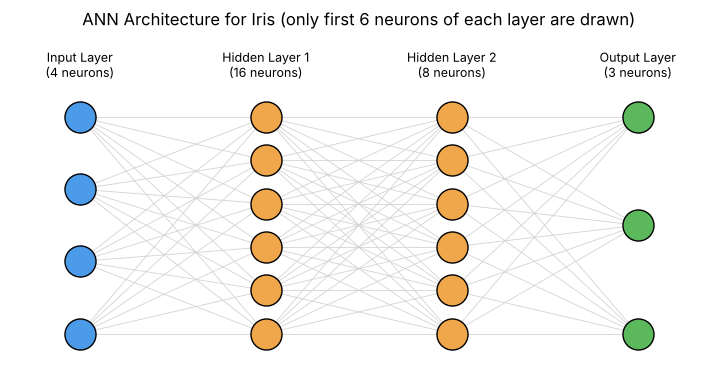

In [7]:
def draw_network(sizes, names, filename, title):
    fig, ax = plt.subplots(figsize=(9, 4.5))
    xs = np.linspace(0.1, 0.9, len(sizes))
    pos = []
    for x, n in zip(xs, sizes):
        shown = min(n, 6)
        ys = np.linspace(0.15, 0.85, shown) if shown > 1 else [0.5]
        pos.append([(x, y) for y in ys])
    for a, b in zip(pos[:-1], pos[1:]):
        for p in a:
            for q in b:
                ax.plot([p[0], q[0]], [p[1], q[1]], color="lightgrey", lw=0.6, zorder=1)
    colors = ["#4c9be8"] + ["#f0a64b"] * (len(sizes) - 2) + ["#5cb85c"]
    for layer, c, nm, n in zip(pos, colors, names, sizes):
        for p in layer:
            ax.scatter(*p, s=500, color=c, edgecolor="black", zorder=2)
        ax.text(layer[0][0], 0.97, f"{nm}\n({n} neurons)", ha="center", va="bottom", fontsize=9)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.12); ax.axis("off")
    ax.set_title(title)
    plt.savefig(filename, dpi=120, bbox_inches="tight")
    plt.show()

draw_network([4, 16, 8, 3], ["Input Layer", "Hidden Layer 1", "Hidden Layer 2", "Output Layer"],
             "Screenshots/02_model_architecture.png", "ANN Architecture for Iris (only first 6 neurons of each layer are drawn)")

## Step 5: Compile the model
I already compiled the model inside `build_model()` using:
- **Optimizer:** Adam
- **Loss:** sparse categorical crossentropy (for integer class labels)
- **Metric:** accuracy

## Step 6: Train the model
Training for 30 epochs with 20% of the training data used for validation.

In [8]:
history = model.fit(X_train, y_train, epochs=30, batch_size=8,
                    validation_split=0.2, verbose=0)

# print the training log in the same style as Keras
log = []
for i in range(30):
    log.append(f"Epoch {i+1:2d}/30 - loss: {history.history['loss'][i]:.4f} - accuracy: {history.history['accuracy'][i]:.4f}"
               f" - val_loss: {history.history['val_loss'][i]:.4f} - val_accuracy: {history.history['val_accuracy'][i]:.4f}")
print("\n".join(log))
save_output_image("TRAINING OUTPUT\n" + "\n".join(log), "Screenshots/03_training_output.png")

Epoch  1/30 - loss: 1.2998 - accuracy: 0.1562 - val_loss: 1.2377 - val_accuracy: 0.1667
Epoch  2/30 - loss: 1.1854 - accuracy: 0.1979 - val_loss: 1.1359 - val_accuracy: 0.2500
Epoch  3/30 - loss: 1.0910 - accuracy: 0.3021 - val_loss: 1.0559 - val_accuracy: 0.3333
Epoch  4/30 - loss: 1.0144 - accuracy: 0.3229 - val_loss: 0.9948 - val_accuracy: 0.4167
Epoch  5/30 - loss: 0.9529 - accuracy: 0.3750 - val_loss: 0.9430 - val_accuracy: 0.3750
Epoch  6/30 - loss: 0.8977 - accuracy: 0.4896 - val_loss: 0.8952 - val_accuracy: 0.5417
Epoch  7/30 - loss: 0.8453 - accuracy: 0.6042 - val_loss: 0.8499 - val_accuracy: 0.5833
Epoch  8/30 - loss: 0.7946 - accuracy: 0.6771 - val_loss: 0.8068 - val_accuracy: 0.5833
Epoch  9/30 - loss: 0.7466 - accuracy: 0.7292 - val_loss: 0.7663 - val_accuracy: 0.6250
Epoch 10/30 - loss: 0.7031 - accuracy: 0.7500 - val_loss: 0.7312 - val_accuracy: 0.6250
Epoch 11/30 - loss: 0.6633 - accuracy: 0.7708 - val_loss: 0.6990 - val_accuracy: 0.6250
Epoch 12/30 - loss: 0.6263 - acc

In [9]:
model.save("iris_ann_basic.keras")
print("Model saved")
print("Final training accuracy  :", round(history.history["accuracy"][-1], 4))
print("Final validation accuracy:", round(history.history["val_accuracy"][-1], 4))

Model saved
Final training accuracy  : 0.8542
Final validation accuracy: 0.7917


## Summary
I built a neural network with 4 input neurons, two hidden layers (16 and 8 neurons) and 3 output neurons. After 30 epochs the training accuracy was about 85.4% and the validation accuracy about 79.2%, and the loss was still going down, which means the model had not finished learning yet. In **Task 3** I train it for 100 epochs and draw the graphs, and in **Task 4** I test it on unseen data.